---
# **Wikipedia Article Categorisation**

### Joseph Nicolas

----

## ◈ Setup

The libraries needed can be seen below.\
**Note:** The warnings do not affect the functionality, the code will run just fine.

In [1]:
# General
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from tqdm import tqdm
from wordcloud import WordCloud

# Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV

# Deep Learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from transformers import AutoModelForSequenceClassification, AutoTokenizer, TrainingArguments, Trainer
from datasets import Dataset

print("\nAll imports successful.")

2026-04-23 03:51:49.582279: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
,2026-04-23 03:51:49.582307: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
,2026-04-23 03:51:49.593371: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
,2026-04-23 03:51:49.615815: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
,To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
,2026-04-23 03:51:50.577190: W tensorflow/compile


,All imports successful.


---
## ◈ Data Loading

**Before training anything, we need to see what we're actually working with.**

The dataset is a large, containing dozens of Wikipedia pages in both English and French. I'm ignoring the French folder entirely.
The English side is 74.1 GB split across multiple .jsonl files. Each file contains the content of many Wikipedia articles. The plan is to grab some of that data and build four different classifiers for article categories.

Kaggle source: https://www.kaggle.com/datasets/wikimedia-foundation/wikipedia-structured-contents

### Loading Data from JSONL Files

In [2]:
# Below is a list of relative file paths of 3 jsonl files
file_paths = [
    "archive/enwiki_namespace_0/enwiki_namespace_0_0.jsonl",
    "archive/enwiki_namespace_0/enwiki_namespace_0_1.jsonl",
    "archive/enwiki_namespace_0/enwiki_namespace_0_2.jsonl"
]

all_records = []  # Will hold every article from all files

for file_path in file_paths:
    print(f"Processing: {file_path}")
    with open(file_path, 'r', encoding='utf-8') as f:
        # tqdm will show progress for the current file
        for line in tqdm(f, desc=f"Reading {file_path.split('/')[-1]}", unit=" articles"):
            # Load the first Wikipedia article then save it to our records
            article = json.loads(line)
            all_records.append(article)

# Convert the list of dictionaries to a DataFrame
df = pd.DataFrame(all_records)

# Show some content and a couple of rows
print("")
df.info()
print("")
df.head()

Processing: archive/enwiki_namespace_0/enwiki_namespace_0_0.jsonl


Reading enwiki_namespace_0_0.jsonl: 309509 articles [00:42, 7364.75 articles/s] 


Processing: archive/enwiki_namespace_0/enwiki_namespace_0_1.jsonl


Reading enwiki_namespace_0_1.jsonl: 311598 articles [00:41, 7423.12 articles/s] 


Processing: archive/enwiki_namespace_0/enwiki_namespace_0_2.jsonl


Reading enwiki_namespace_0_2.jsonl: 314347 articles [01:31, 3426.59 articles/s] 



,<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 935454 entries, 0 to 935453
,Data columns (total 17 columns):
, #   Column               Non-Null Count   Dtype 
,---  ------               --------------   ----- 
, 0   name                 935454 non-null  object
, 1   identifier           935454 non-null  int64 
, 2   version              935454 non-null  object
, 3   event                935454 non-null  object
, 4   url                  935454 non-null  object
, 5   date_created         465 non-null     object
, 6   date_modified        935454 non-null  object
, 7   is_part_of           935454 non-null  object
, 8   in_language          935454 non-null  object
, 9   license              935454 non-null  object
, 10  description          764450 non-null  object
, 11  sections             935302 non-null  object
, 12  abstract             933899 non-null  object
, 13  main_entity          934609 non-null  object
, 14  additional_entities  934616 non-null  object
, 15  infoboxes   

,name,identifier,version,event,url,date_created,date_modified,is_part_of,in_language,license,description,sections,abstract,main_entity,additional_entities,infoboxes,image
0,Not Again SU,76716259,"{'identifier': 1220413474, 'comment': 'Added #...",{'identifier': 'fa3cae5b-8707-4f55-9fab-5baa4c...,https://en.wikipedia.org/wiki/Not_Again_SU,2024-04-23T16:50:32Z,2024-04-23T16:53:55Z,"{'identifier': 'enwiki', 'url': 'https://en.wi...",{'identifier': 'en'},[{'name': 'Creative Commons Attribution-ShareA...,"Student organization in Syracuse, New York","[{'type': 'section', 'name': 'Abstract'}, {'ty...",NaN,NaN,NaN,NaN,NaN
1,Mike Ross (Suits),76727681,"{'identifier': 1220574416, 'comment': 'Request...",{'identifier': '22366970-ddf7-43dc-8cec-941de1...,https://en.wikipedia.org/wiki/Mike_Ross_(Suits),2024-04-24T17:12:05Z,2024-04-24T17:14:10Z,"{'identifier': 'enwiki', 'url': 'https://en.wi...",{'identifier': 'en'},[{'name': 'Creative Commons Attribution-ShareA...,An American Legal drama series from 2011-2019,"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT List of Suits characters#Mike Ross,"{'identifier': 'Q125388612', 'url': 'https://w...","[{'identifier': 'Q125388612', 'url': 'https://...",NaN,NaN
2,Second Polish republic,76744378,"{'identifier': 1220875620, 'comment': '[[WP:AE...",{'identifier': '552624d6-5c55-45ef-a8e3-945335...,https://en.wikipedia.org/wiki/Second_Polish_re...,2024-04-26T13:30:10Z,2024-04-26T13:30:10Z,"{'identifier': 'enwiki', 'url': 'https://en.wi...",{'identifier': 'en'},[{'name': 'Creative Commons Attribution-ShareA...,Country in Central and Eastern Europe (1918–1939),"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT #Second Polish Republic,NaN,NaN,NaN,NaN
3,Left-to-right script,76735997,"{'identifier': 1220716997, 'comment': 'create ...",{'identifier': 'aae6c4ee-bf95-4dc0-942d-5eea53...,https://en.wikipedia.org/wiki/Left-to-right_sc...,2024-04-25T13:58:39Z,2024-04-25T13:58:39Z,"{'identifier': 'enwiki', 'url': 'https://en.wi...",{'identifier': 'en'},[{'name': 'Creative Commons Attribution-ShareA...,Convention of symbols representing language,"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT Writing system#Directionality,NaN,NaN,NaN,NaN
4,1442 in France,58128987,"{'identifier': 1145356533, 'comment': 'Alter: ...",{'identifier': 'c4526432-0a4a-42ed-8ef7-54827c...,https://en.wikipedia.org/wiki/1442_in_France,NaN,2023-03-18T18:38:51Z,"{'identifier': 'enwiki', 'url': 'https://en.wi...",{'identifier': 'en'},[{'name': 'Creative Commons Attribution-ShareA...,List of events in the year 1442,"[{'type': 'section', 'name': 'Abstract', 'has_...",Events from the year 1442 in France,"{'identifier': 'Q56292328', 'url': 'https://ww...","[{'identifier': 'Q56292328', 'url': 'https://w...","[{'type': 'infobox', 'name': 'Year in France h...",NaN


### Relevant Information

In [3]:
df[['name', 'url', 'description', 'sections', 'abstract']].head()

,name,url,description,sections,abstract
0,Not Again SU,https://en.wikipedia.org/wiki/Not_Again_SU,"Student organization in Syracuse, New York","[{'type': 'section', 'name': 'Abstract'}, {'ty...",NaN
1,Mike Ross (Suits),https://en.wikipedia.org/wiki/Mike_Ross_(Suits),An American Legal drama series from 2011-2019,"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT List of Suits characters#Mike Ross
2,Second Polish republic,https://en.wikipedia.org/wiki/Second_Polish_re...,Country in Central and Eastern Europe (1918–1939),"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT #Second Polish Republic
3,Left-to-right script,https://en.wikipedia.org/wiki/Left-to-right_sc...,Convention of symbols representing language,"[{'type': 'section', 'name': 'Abstract', 'has_...",REDIRECT Writing system#Directionality
4,1442 in France,https://en.wikipedia.org/wiki/1442_in_France,List of events in the year 1442,"[{'type': 'section', 'name': 'Abstract', 'has_...",Events from the year 1442 in France


**Most of these columns are useless for classification.** The ones that actually matter are `description`, `sections`, and `abstract`. The article `name` and `url` columns are included for reference, making it easier to identify each article and understand what the corresponding fields contain.

I didn't pick these three at random. I dug into the raw JSON and reviewed several articles to understand where the actual text is stored. Most of the article content is contained in `sections`, while `description` provides some additional information. Not every article has an `abstract`, but many do, and it adds useful context when available.

The main complication is that `sections` isn't a plain-text field. Its content is nested within lists and dictionaries under **`has_parts`**. We'll need to account for this structure when writing the functions to extract and combine the text.

---
## ◈ Data Preprocessing

**First step: get clean, usable text from the large JSONL file.**

The real content is buried inside nested lists and dictionaries under sections. The two functions below dig through that structure and pull out all the actual paragraphs, then combine them with the abstract and description.

### Extraction & Preparation of Data

In [4]:
# Make a new dataframe as to allow reruns without editing the original dataframe
df_ext = df.copy()  # ext is short for extraction

def extract_text_from_parts(parts):
    """Recursively extract all 'value' strings from nested has_parts structures."""
    collected_text = []
    if isinstance(parts, list):
        for element in parts:
            if isinstance(element, dict):
                if 'value' in element:
                    collected_text.append(element['value'])
                if 'has_parts' in element:
                    collected_text.extend(extract_text_from_parts(element['has_parts']))
    return collected_text


def extract_article_text(article_row):
    """Combine sections, abstract, and description into a single article text."""
    all_text_pieces = []

    # Sections (main body)
    sections_field = article_row.get('sections')
    if isinstance(sections_field, list):
        for section in sections_field:
            if isinstance(section, dict) and 'has_parts' in section:
                all_text_pieces.extend(extract_text_from_parts(section['has_parts']))

    # Abstract (skip 'REDIRECT')
    abstract = article_row.get('abstract')
    if isinstance(abstract, str) and abstract.strip():
        if not abstract.strip().upper().startswith('REDIRECT'):
            all_text_pieces.append(abstract.strip())

    # Description
    description = article_row.get('description')
    if isinstance(description, str) and description.strip():
        all_text_pieces.append(description.strip())

    full_text = ' '.join(all_text_pieces).strip()
    return full_text if len(full_text) >= 100 else None 


# Apply extraction function to each row and create a new column
df_ext['full_text'] = df_ext.apply(extract_article_text, axis=1)

# Drop rows where extraction failed (None returned)
df_ext = df_ext.dropna(subset=['full_text'])

print(f"Articles with valid text: {len(df_ext)} (total dropped from original: {len(df) - len(df_ext)})")

# Show a preview of some text extracted
sample_text = df_ext['full_text'].iloc[0]
preview = sample_text[:500] + "..." if len(sample_text) > 500 else sample_text
print(f"\nSample full_text preview (first 500 chars):\n{preview}")

Articles with valid text: 933907 (total dropped from original: 1547)
,
,Sample full_text preview (first 500 chars):
,The hashtag and student led organization #NotAgainSU began circulating after several racist incidents occurred on the campus of Syracuse University, during the academic course of 2019-2021. Initial reports of racist paraphernalia occurred early November in the dorm buildings of first- and second-year undergraduate students. After nearly a month of daily reports, Syracuse students organized a sit-in where they occupied, and created an elaborate list of 19 demands for Chancellor Kent Syverud to si...


The extraction got just over **933,000 articles** with actual content. The preview shows the first chunk of text from a page about the #NotAgainSU student movement. This shows a sample of what the data we collected looks like

### Assigning Categories to Articles

After extracting the main text (the features), I will need to create the high-level categories (the target). The labels/categories will be created based on certain keyboards that we set.

In [5]:
df_cat = df_ext.copy() # cat is short for category

def assign_category(row):
    """Assign a category based on whole‑word keyword matching."""
    # Collect text from the appropriate fields only
    parts = []
    for field in ['description', 'abstract', 'name']:
        val = row.get(field)
        if isinstance(val, str):
            parts.append(val)
    text = ' '.join(parts).lower()
    
    # Split into a set of unique words for fast keyword checking
    # A set was used because we can check for intersection using a prebuilt function
    words = set(text.split())
    
    # Refined keyword sets that will be used to compare whole words from the Wikipedia text
    keywords = {
        'Science': {
            'science', 'physics', 'chemistry', 'biology', 'astronomy', 'mathematics',
            'scientist', 'research', 'quantum', 'molecule', 'gene', 'species', 'evolution',
            'laboratory', 'experiment', 'theory', 'genetics', 'neuroscience', 'geology',
            'ecology', 'zoology', 'botany', 'biochemistry', 'particle', 'atom', 'cell',
            'organism', 'fossil', 'telescope', 'microscope', 'equation', 'hypothesis',
            'biologist', 'chemist', 'physicist', 'astronomer', 'genome', 'dna', 'rna'
        },
        'History': {
            'history', 'century', 'ancient', 'war', 'battle', 'king', 'queen', 'empire',
            'dynasty', 'revolution', 'medieval', 'roman', 'greek', 'civilization',
            'wwi', 'wwii', 'treaty', 'independence', 'colonial', 'monarchy',
            'president', 'historical', 'archaeology', 'artifact', 'manuscript',
            'chronicle', 'reign', 'conquest', 'rebellion', 'timeline', 'era', 'bc',
            'ad', 'bce', 'ce', 'vikings', 'ottoman', 'byzantine', 'cold', 'war'
        },
        'Sports': {
            'sport', 'football', 'soccer', 'basketball', 'baseball', 'tennis', 'cricket',
            'rugby', 'golf', 'hockey', 'volleyball', 'swimming', 'athletics', 'olympic',
            'championship', 'league', 'tournament', 'player', 'team', 'coach', 'stadium',
            'match', 'goal', 'score', 'medal', 'nba', 'nfl', 'fifa', 'uefa', 'athlete',
            'goalkeeper', 'pitcher', 'quarterback', 'wicket', 'grand', 'slam'
        },
        'Technology': {
            'technology', 'software', 'hardware', 'computer', 'internet', 'digital',
            'programming', 'algorithm', 'data', 'network', 'ai', 'robotics',
            'cybersecurity', 'cloud', 'app', 'mobile', 'device', 'startup', 'code',
            'developer', 'database', 'server', 'encryption', 'blockchain', 'iot',
            'virtual', 'reality', 'machine', 'learning', 'artificial', 'intelligence'
        },
        'Arts': {
            'art', 'music', 'film', 'movie', 'painting', 'sculpture', 'artist', 'album',
            'band', 'singer', 'actor', 'director', 'literature', 'book', 'novel', 'poem',
            'poetry', 'theatre', 'drama', 'cinema', 'dance', 'ballet', 'opera', 'symphony',
            'gallery', 'museum', 'exhibition', 'photography', 'design', 'fashion',
            'painter', 'composer', 'musician', 'playwright', 'screenwriter', 'choreographer'
        },
        'Geography': {
            'geography', 'city', 'town', 'village', 'country', 'river', 'mountain',
            'island', 'continent', 'ocean', 'sea', 'lake', 'desert', 'forest', 'valley',
            'peninsula', 'coast', 'climate', 'population', 'capital', 'region', 'province',
            'state', 'territory', 'landscape', 'map', 'cartography', 'gps', 'latitude',
            'longitude', 'equator', 'tropic', 'arctic', 'antarctic', 'hemisphere'
        },
        'Politics': {
            'politics', 'government', 'election', 'president', 'senate', 'congress',
            'parliament', 'democracy', 'republic', 'monarchy', 'dictatorship', 'policy',
            'law', 'legislation', 'party', 'vote', 'campaign', 'diplomacy', 'treaty',
            'sanction', 'protest', 'activist', 'ideology', 'conservative', 'liberal',
            'socialist', 'communist', 'un', 'nato', 'eu', 'brexit', 'referendum'
        },
        'Health': {
            'health', 'medicine', 'disease', 'cancer', 'virus', 'bacteria', 'pandemic',
            'vaccine', 'hospital', 'doctor', 'nurse', 'patient', 'surgery', 'pharmacy',
            'drug', 'treatment', 'therapy', 'nutrition', 'diet', 'exercise', 'fitness',
            'wellness', 'clinic', 'diagnosis', 'symptom', 'immunology', 'cardiology',
            'neurology', 'covid', 'influenza', 'diabetes', 'hypertension', 'obesity'
        },
        'Business': {
            'business', 'company', 'corporation', 'industry', 'economy', 'market',
            'finance', 'investment', 'stock', 'trade', 'commerce', 'entrepreneur',
            'startup', 'revenue', 'profit', 'loss', 'ceo', 'board', 'shareholder',
            'merger', 'acquisition', 'banking', 'insurance', 'retail', 'wholesale',
            'supply', 'chain', 'logistics', 'marketing', 'sales', 'consumer', 'product'
        },
        'Education': {
            'education', 'school', 'university', 'college', 'student', 'teacher',
            'professor', 'academic', 'curriculum', 'degree', 'bachelor', 'master',
            'phd', 'research', 'scholarship', 'learning', 'teaching', 'pedagogy',
            'classroom', 'course', 'literacy', 'vocational', 'training', 'elementary',
            'secondary', 'kindergarten', 'library', 'textbook', 'syllabus', 'exam'
        }
    }
    
    # Check intersection between words in text and each category's keywords
    for category, kw_set in keywords.items():
        if words.intersection(kw_set):
            return category
    return None

# Apply assignment and add a column to the Dataframe
df_cat['category'] = df_cat.apply(assign_category, axis=1)

# Keep only successfully categorized articles 
df_cat = df_cat.dropna(subset=['category'])
print(f"Articles with an assigned category: {len(df_cat)} (total dropped from original: {len(df) - len(df_cat)})")
print(f"\n•{df_cat['category'].value_counts()}")

Articles with an assigned category: 725273 (total dropped from original: 210181)
,
,•category
,Sports        153797
,Geography     153419
,Science       117178
,Arts          107306
,History       103456
,Politics       29047
,Technology     24006
,Education      15319
,Business       15174
,Health          6571
,Name: count, dtype: int64


After filtering based on empty categories, we've got about **725,000 articles**.\
The distribution is uneven, which is common in real life however we will want to fix it. So balancing is next.

### Balance & Split

**We can't train on an imbalanced dataset.**

I'm keeping only categories with at least 100,000 articles, which will leave us with five categories: Sports, Geography, Science, Arts, and History.
Then I'm randomly sampling exactly 100,000 articles from each, giving a clean 500,000‑article dataset with equal representation.

In [6]:
sample_size = 100000

# Keep only categories with enough articles
categories = df_cat['category'].value_counts()
valid_cats = categories[categories >= sample_size].index.tolist()
print(f"Categories kept: {valid_cats}")

# Sample and balance
bal_parts = []
for cat in valid_cats:
    subset = df_cat[df_cat['category'] == cat]
    bal_parts.append(subset.sample(n=sample_size, random_state=50))

# Combine all the sampled pieces into one new DataFrame
df_bal = pd.concat(bal_parts, ignore_index=True)
print(f"Balanced dataset size: {len(df_bal)}")
print(f"\n•{df_bal['category'].value_counts()}")

# Split into 80% train and 20% test with stratification
X_train, X_test, y_train, y_test = train_test_split(
    df_bal['full_text'],
    df_bal['category'],
    test_size=0.2,
    random_state=50,
    stratify=df_bal['category']
)

print(f"\nTraining samples: {len(X_train)}")
print(f"Test samples:     {len(X_test)}")

Categories kept: ['Sports', 'Geography', 'Science', 'Arts', 'History']
,Balanced dataset size: 500000
,
,•category
,Sports       100000
,Geography    100000
,Science      100000
,Arts         100000
,History      100000
,Name: count, dtype: int64
,
,Training samples: 400000
,Test samples:     100000


Now after the balancing, there are **400,000 articles for training** and **100,000 held out for testing**. The split is stratified so each category stays balanced in both sets.

---
## ◈ Exploratory Data Analysis 

Before throwing models at the data, let's check the category balance (should be perfectly even now) and see what words dominate the training text. This can be done via visualisations which are below.

### Visualisations

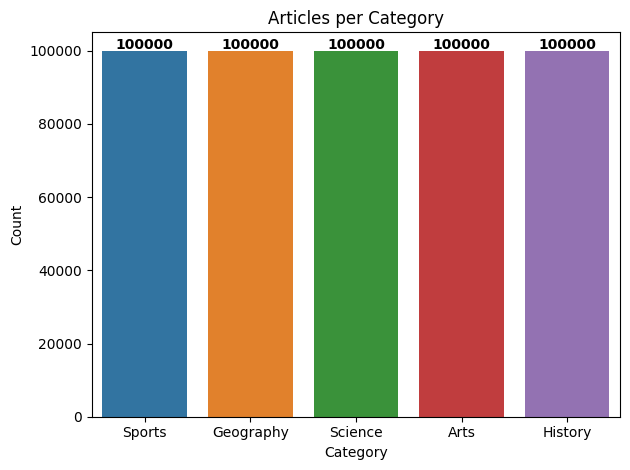

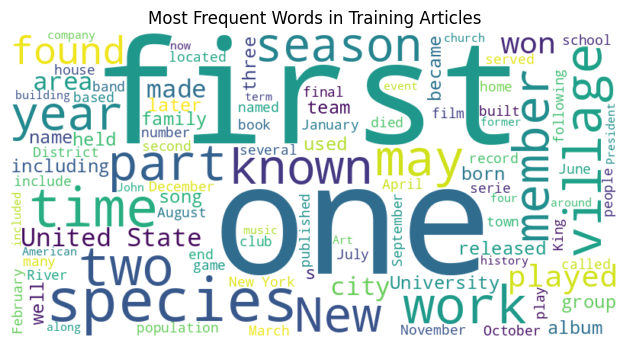

In [41]:
# Visualisation 1: Balanced Category Distribution 
cat_counts = df_bal['category'].value_counts()
custom_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'] # I wanted each bar to be a different colour
sns.barplot(x=cat_counts.index, y=cat_counts.values, hue=cat_counts.index, palette=custom_colors, legend=False)
plt.title('Articles per Category')
plt.xlabel('Category')
plt.ylabel('Count')
for i, v in enumerate(cat_counts.values):
    plt.text(i, v + 500, f"{v}", ha='center', fontweight='bold') # Show the numbers on each bar
plt.tight_layout()
plt.savefig('./articles_bar_chart.png', dpi=600)
plt.show()

# Visualisation 2: Word Cloud of Training Text 
# To do this I combine a sample (first 10000) of training texts
sample_texts = ' '.join(X_train.head(10000).tolist())
wordcloud = WordCloud(width=800, height=400, background_color='white',
                      max_words=100, colormap='viridis').generate(sample_texts)

print("") # Put some space below the previous image
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Words in Training Articles')
plt.tight_layout()
plt.savefig('./word_cloud.png', dpi=600)
plt.show()

The bar chart confirms every category has exactly 100,000 articles. The word cloud shows some terms like "species," "population," "work," and some others that aren't as useful like "one", "two", or "first".

---
## ◈ Machine Learning Models

This section will delve into the two traditional machine learning algorithms and some hyperparameter tuning.

### ◇ Feature Extraction (TF-IDF)

Traditional ML models don't read text, instead they read numbers.
TF‑IDF converts each article into a numerical vector based on word importance. We're using the top 5,000 words plus bigrams (two‑word phrases) to capture a bit of context.

In [8]:
def clean_text(text):
    """Lowercase, remove punctuation/digits and  extra spaces."""
    text = text.lower()
    text = re.sub(r'[^\w\s]', ' ', text)     # punctuation → space
    text = re.sub(r'\d+', ' ', text)         # digits → space
    text = re.sub(r'\s+', ' ', text).strip() # collapse multiple spaces into one
    return text

# Apply the cleaning to both the train and test texts
X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)

# Create TF‑IDF vectors (top 5000 words + bigrams)
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))
X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

print(f"TF‑IDF train shape: {X_train_tfidf.shape}")
print(f"TF‑IDF test shape:  {X_test_tfidf.shape}")

TF‑IDF train shape: (400000, 5000)
,TF‑IDF test shape:  (100000, 5000)


### ◇ Naive Bayes

The first model is a simple, and fast one. I will use it as a baseline. I'm using alpha=0.1 for a bit of smoothing.

#### Original Model

In [9]:
# Train
nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate
acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb, rec_nb, f1_nb, _ = precision_recall_fscore_support(y_test, y_pred_nb, average='weighted')

# Print results
print("Naive Bayes Results:")
print(f"Accuracy:  {acc_nb:.4f}")
print(f"Precision: {prec_nb:.4f}")
print(f"Recall:    {rec_nb:.4f}")
print(f"F1-score:  {f1_nb:.4f}")

Naive Bayes Results:
,Accuracy:  0.8104
,Precision: 0.8162
,Recall:    0.8104
,F1-score:  0.8122


For a baseline **81.04% accuracy** and **81.22% F1-score** is quite good. 

#### Hyperparameter Tuning

Using a quick `GridSearchCV()` over alpha values to see if a different smoothing parameter helps.

In [10]:
# Define alpha values to test
param_grid = {'alpha': [0.01, 0.1, 0.5]}

# Grid search with 3‑fold cross‑validation
grid_nb = GridSearchCV(
    MultinomialNB(),
    param_grid,
    cv=3,
    scoring='f1_weighted',
    verbose=1
)
grid_nb.fit(X_train_tfidf, y_train)

print(f"\nBest alpha: {grid_nb.best_params_['alpha']}")

# Evaluate the best model on the test set
best_nb = grid_nb.best_estimator_
y_pred_tuned = best_nb.predict(X_test_tfidf)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
prec_tuned, rec_tuned, f1_tuned, _ = precision_recall_fscore_support(
    y_test, y_pred_tuned, average='weighted'
)

print("\nTuned Naive Bayes Results:")
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"Precision: {prec_tuned:.4f}")
print(f"Recall:    {rec_tuned:.4f}")
print(f"F1-score:  {f1_tuned:.4f}")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
,
,Best alpha: 0.5
,
,Tuned Naive Bayes Results:
,Accuracy:  0.8103
,Precision: 0.8161
,Recall:    0.8103
,F1-score:  0.8121


The tuned Naive Bayes did very similarly to the original model. \
The alpha at 0.1 (from the previous cell) or 0.5 (this cell) are extremely close.

### ◇ Support Vector Machine (SVM)

SVMs often shine on high‑dimensional data. In this case I'm using LinearSVC with default C=1.0 and enough iterations to converge.

#### Original Model

In [11]:
# Train
svm_model = LinearSVC(C=1.0, max_iter=2000, random_state=50)
svm_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm, rec_svm, f1_svm, _ = precision_recall_fscore_support(y_test, y_pred_svm, average='weighted')

# Print results
print("SVM Results:")
print(f"Accuracy:  {acc_svm:.4f}")
print(f"Precision: {prec_svm:.4f}")
print(f"Recall:    {rec_svm:.4f}")
print(f"F1-score:  {f1_svm:.4f}")

SVM Results:
,Accuracy:  0.8987
,Precision: 0.8988
,Recall:    0.8987
,F1-score:  0.8983


**89.87% accuracy** compared to the **81.04% of Naive Bayes** is a nice improvement which shows it does indeed classify better. 

#### Hyperparameter Tuning

In [12]:
# Define C values to test (regularisation strength)
param_grid = {'C': [0.1, 0.5, 1.0]}

# Grid search with 3‑fold cross‑validation
grid_svm = GridSearchCV(
    LinearSVC(max_iter=2000, random_state=50),
    param_grid,
    cv=3,
    scoring='f1_weighted',
    verbose=1
)
grid_svm.fit(X_train_tfidf, y_train)

print(f"\nBest C: {grid_svm.best_params_['C']}")

# Evaluate the best model on the test set
best_svm = grid_svm.best_estimator_
y_pred_tuned = best_svm.predict(X_test_tfidf)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
prec_tuned, rec_tuned, f1_tuned, _ = precision_recall_fscore_support(
    y_test, y_pred_tuned, average='weighted'
)

print("\nTuned SVM Results:")
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"Precision: {prec_tuned:.4f}")
print(f"Recall:    {rec_tuned:.4f}")
print(f"F1-score:  {f1_tuned:.4f}")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
,
,Best C: 1.0
,
,Tuned SVM Results:
,Accuracy:  0.8987
,Precision: 0.8988
,Recall:    0.8987
,F1-score:  0.8983


Similarly to the tuned Naive Bayes, this result is barely improved in terms of accuracy.\
This also confirmed that the original C we picked turned out to be the best. Sometimes that is the case other times it isn't.

---
## ◈ Deep Learning Models

Now onto the **neural networks** which each have their own preprocessing steps and respective architectures.

### ◇ BiLSTM

First up is a Bidirectional LSTM. This model reads text sequentially and can capture context from both directions.

#### Tokenization & Labelling

In [13]:
# Set maximum length and number of words
MAX_VOCAB = 10000
MAX_LEN = 200

# Tokenizer (fit on cleaned training text)
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_clean)

# Convert text to sequences and pad
X_train_seq = tokenizer.texts_to_sequences(X_train_clean)
X_test_seq = tokenizer.texts_to_sequences(X_test_clean)
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

# Encode string labels to integers
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = len(le.classes_)

print(f"Padded train shape: {X_train_pad.shape}")
print(f"Number of classes:  {num_classes}")

Padded train shape: (400000, 200)
,Number of classes:  5


#### Train & Evaluate

In [14]:
# Model architecture
model_bilstm = Sequential([
    Embedding(MAX_VOCAB, 128, input_length=MAX_LEN),
    Bidirectional(LSTM(64, dropout=0.2, return_sequences=False)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

model_bilstm.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train
history_bilstm = model_bilstm.fit(
    X_train_pad, y_train_enc,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate
y_pred_bilstm_probs = model_bilstm.predict(X_test_pad)
y_pred_bilstm = y_pred_bilstm_probs.argmax(axis=1)

acc_bilstm = accuracy_score(y_test_enc, y_pred_bilstm)
prec_bilstm, rec_bilstm, f1_bilstm, _ = precision_recall_fscore_support(
    y_test_enc, y_pred_bilstm, average='weighted'
)

print("\nBiLSTM Results:")
print(f"Accuracy:  {acc_bilstm:.4f}")
print(f"Precision: {prec_bilstm:.4f}")
print(f"Recall:    {rec_bilstm:.4f}")
print(f"F1-score:  {f1_bilstm:.4f}")

2026-04-23 04:08:39.544553: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
,2026-04-23 04:08:39.983930: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
,2026-04-23 04:08:39.986896: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L34

Epoch 1/10


2026-04-23 04:08:45.669357: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
,2026-04-23 04:08:45.813097: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f00d26bfd80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
,2026-04-23 04:08:45.813121: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
,2026-04-23 04:08:45.822584: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
,WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
,I0000 00:00:1776913725.886347  218797 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


5000/5000 [==============================] - 95s 18ms/step - loss: 0.3537 - accuracy: 0.8799 - val_loss: 0.2310 - val_accuracy: 0.9139
,Epoch 2/10
,5000/5000 [==============================] - 62s 12ms/step - loss: 0.2145 - accuracy: 0.9212 - val_loss: 0.2101 - val_accuracy: 0.9222
,Epoch 3/10
,5000/5000 [==============================] - 62s 12ms/step - loss: 0.1738 - accuracy: 0.9350 - val_loss: 0.1902 - val_accuracy: 0.9324
,Epoch 4/10
,5000/5000 [==============================] - 63s 13ms/step - loss: 0.1445 - accuracy: 0.9465 - val_loss: 0.1968 - val_accuracy: 0.9308
,Epoch 5/10
,5000/5000 [==============================] - 62s 12ms/step - loss: 0.1151 - accuracy: 0.9568 - val_loss: 0.2144 - val_accuracy: 0.9298
,Epoch 6/10
,5000/5000 [==============================] - 62s 12ms/step - loss: 0.0903 - accuracy: 0.9662 - val_loss: 0.2444 - val_accuracy: 0.9276
,3125/3125 [==============================] - 16s 5ms/step
,
,BiLSTM Results:
,Accuracy:  0.9331
,Precision: 0.9331
,Recall: 

So far it is the best model with around **93.31% accuracy**, which was expected.\
This did take some time to train however, so the tradeoff depends on the use case.

### ◇ DistilBERT

The last model is a transformer: **DistilBERT**.

This is a distilled version of BERT, being faster, lighter and almost as accurate. We'll fine‑tune it on our Wikipedia categories using Hugging Face's Trainer API.

**Note:** The data had to be cut here as it would either take too long or crash

#### Subset & Tokenization

In [15]:
# Create a smaller subset as the full data takes too long
subset_train_size = 50000  
subset_test_size  = 10000

# Random sample (replace=False ensures there are no duplicates)
train_idx = np.random.choice(len(X_train), size=subset_train_size, replace=False)
test_idx  = np.random.choice(len(X_test),  size=subset_test_size,  replace=False)

X_train_sub = X_train.iloc[train_idx].reset_index(drop=True)
y_train_sub = y_train.iloc[train_idx].reset_index(drop=True)
X_test_sub  = X_test.iloc[test_idx].reset_index(drop=True)
y_test_sub  = y_test.iloc[test_idx].reset_index(drop=True)

print(f"Subset sizes: Train = {len(X_train_sub)}, Test = {len(X_test_sub)}")

# Label encoding 
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_sub)
y_test_enc  = le.transform(y_test_sub)
num_classes = len(le.classes_)
print(f"Classes: {list(le.classes_)}")

# Load tokenizer
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Build Hugging Face datasets from raw texts first
train_dataset = Dataset.from_dict({'text': X_train_sub.tolist(), 'label': y_train_enc.tolist()})
test_dataset  = Dataset.from_dict({'text': X_test_sub.tolist(),  'label': y_test_enc.tolist()})

# Tokenize using batched mapping (processes in chunks)
def tokenize_function(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        padding=True,
        max_length=128
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset  = test_dataset.map(tokenize_function, batched=True)

# Set format for PyTorch Trainer
train_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
test_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

print("Tokenization complete. Datasets ready.")

Subset sizes: Train = 50000, Test = 10000
,Classes: ['Arts', 'Geography', 'History', 'Science', 'Sports']


Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Tokenization complete. Datasets ready.


#### Train & Evaluate

In [16]:
# Load model
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_classes
)

# Training arguements
training_args = TrainingArguments(
    output_dir="./distilbert_results",
    eval_strategy="epoch",
    save_strategy="no",
    per_device_train_batch_size=2,      
    gradient_accumulation_steps=8,      # Effective batch = 16
    per_device_eval_batch_size=2,
    num_train_epochs=3,
    learning_rate=2e-5,
    fp16=True,                          # Half precision saves memory
    logging_steps=100,
    report_to="none",
    dataloader_num_workers=0,
    gradient_checkpointing=True,        # Trades compute for lower memory
    disable_tqdm=True,               
    remove_unused_columns=False
)

# Metrics function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

# Train
trainer.train()

# Evaluation
eval_results = trainer.evaluate()
acc_bert   = eval_results['eval_accuracy']
prec_bert  = eval_results['eval_precision']
rec_bert   = eval_results['eval_recall']
f1_bert    = eval_results['eval_f1']

print("\nDistilBERT Results (on subset):")
print(f"Accuracy:  {acc_bert:.4f}")
print(f"Precision: {prec_bert:.4f}")
print(f"Recall:    {rec_bert:.4f}")
print(f"F1-score:  {f1_bert:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
,Key                     | Status     | 
,------------------------+------------+-
,vocab_projector.bias    | UNEXPECTED | 
,vocab_layer_norm.weight | UNEXPECTED | 
,vocab_transform.weight  | UNEXPECTED | 
,vocab_transform.bias    | UNEXPECTED | 
,vocab_layer_norm.bias   | UNEXPECTED | 
,classifier.bias         | MISSING    | 
,classifier.weight       | MISSING    | 
,pre_classifier.weight   | MISSING    | 
,pre_classifier.bias     | MISSING    | 
,
,Notes:
,- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
,- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '8.425', 'grad_norm': '32.9', 'learning_rate': '1.979e-05', 'epoch': '0.032'}
,{'loss': '4.744', 'grad_norm': '36.21', 'learning_rate': '1.958e-05', 'epoch': '0.064'}
,{'loss': '4.599', 'grad_norm': '35.37', 'learning_rate': '1.937e-05', 'epoch': '0.096'}
,{'loss': '3.92', 'grad_norm': '32.2', 'learning_rate': '1.916e-05', 'epoch': '0.128'}
,{'loss': '3.549', 'grad_norm': '52.14', 'learning_rate': '1.894e-05', 'epoch': '0.16'}
,{'loss': '3.296', 'grad_norm': '34.43', 'learning_rate': '1.873e-05', 'epoch': '0.192'}
,{'loss': '3.422', 'grad_norm': '31.33', 'learning_rate': '1.852e-05', 'epoch': '0.224'}
,{'loss': '3.439', 'grad_norm': '25.62', 'learning_rate': '1.83e-05', 'epoch': '0.256'}
,{'loss': '2.939', 'grad_norm': '53.38', 'learning_rate': '1.809e-05', 'epoch': '0.288'}
,{'loss': '3.192', 'grad_norm': '48.2', 'learning_rate': '1.788e-05', 'epoch': '0.32'}
,{'loss': '3.114', 'grad_norm': '45.54', 'learning_rate': '1.766e-05', 'epoch': '0.352'}
,{'loss': '2.854', 'grad_norm

---
This model performed the best at an **accuracy of 93.56%** and an **F1-score of 93.54%**, which was expected but also took the longest to train.

**Note:** Make sure to uncompact the output to be able to scroll down to see the results. Otherwise it will look like it didn't run.

---
## ◈ Results

Adding up the data we have collected, we can see how all four models performed below.

### Visualisations

📋 Model Performance Summary


,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.8104,0.8162,0.8104,0.8122
1,SVM,0.8987,0.8988,0.8987,0.8983
2,BiLSTM,0.9331,0.9331,0.9331,0.9331
3,DistilBERT,0.9356,0.9356,0.9356,0.9354


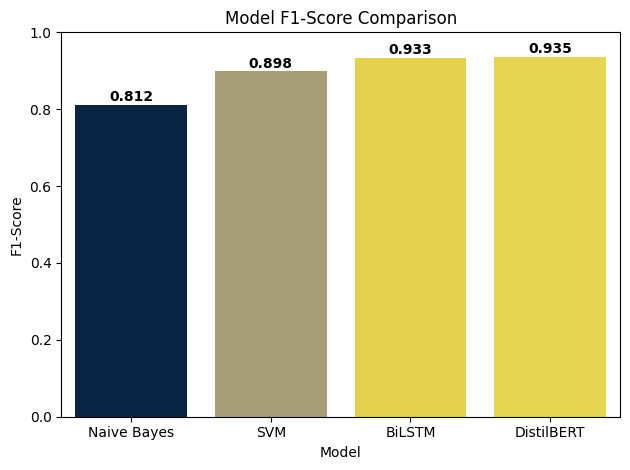

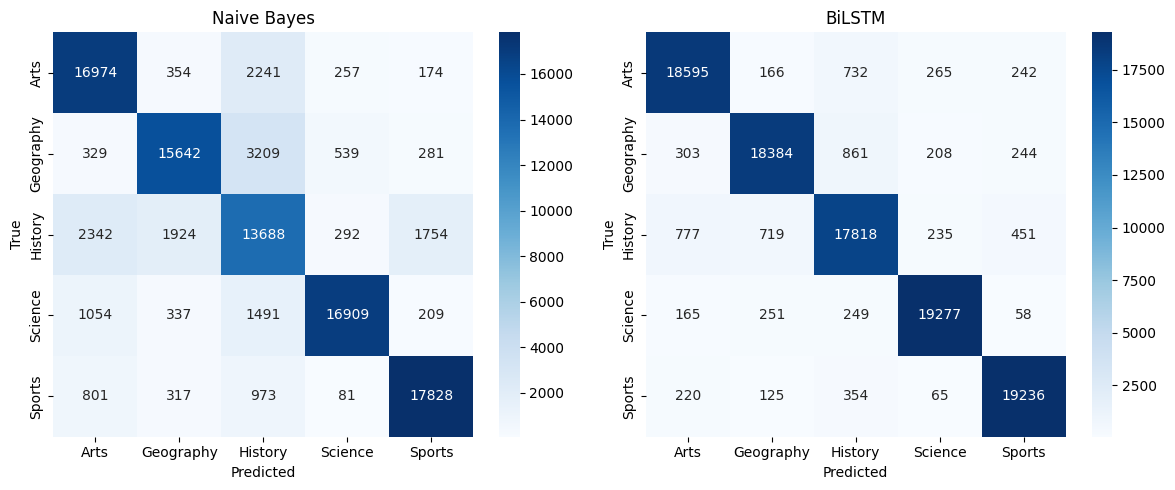

In [49]:
# Summary Table
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM', 'BiLSTM', 'DistilBERT'],
    'Accuracy': [acc_nb, acc_svm, acc_bilstm, acc_bert],
    'Precision': [prec_nb, prec_svm, prec_bilstm, prec_bert],
    'Recall': [rec_nb, rec_svm, rec_bilstm, rec_bert],
    'F1-Score': [f1_nb, f1_svm, f1_bilstm, f1_bert]
})

print("📋 Model Performance Summary")
display(results.round(4))

# Visualisation 1: Bar chart of F1-scores
bars = sns.barplot(data=results, x='Model', y='F1-Score', hue="F1-Score", palette='cividis', legend=False)
plt .title('Model F1-Score Comparison')
plt.ylim(0, 1)
for i, v in enumerate(results['F1-Score']):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center', fontweight='bold') # Show the numbers on each bar
plt.tight_layout()
plt.savefig('./f1_scores_barplot.png', dpi=600)
plt.show()

# Visualisation 2: Confusion matrices — Naive Bayes vs. BiLSTM
# Encode the full test labels and Naive Bayes predictions
y_test_full_enc = le.transform(y_test)
y_pred_nb_enc   = le.transform(y_pred_nb)

# Prepare a figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Naive Bayes
cm_nb = confusion_matrix(y_test_full_enc, y_pred_nb_enc)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('Naive Bayes')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# BiLSTM
cm_bilstm = confusion_matrix(y_test_full_enc, y_pred_bilstm)
sns.heatmap(cm_bilstm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('BiLSTM')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.savefig('./confusion_matrices.png', dpi=600)
plt.show()

To wrap things up, each model ran as expected, which was honestly a bit surprising. The baseline Naive Bayes reached **81.04% accuracy**. For such a simple model, it performed respectably well. SVM followed with **89.87%**.

Both traditional models saw minimal change from hyperparameter tuning, likely reflecting the narrow range of values tested. Tuning can still squeeze out extra performance, but here the defaults were already solid.

The two deep learning models finished very close. DistilBERT edged out the BiLSTM by a slim margin (**93.56%** vs **93.31%**), yet that small gain came at a steep training cost. Even with a distilled architecture and pre‑trained weights, DistilBERT took the longest to train. Lastly, the confusion matrices show the BiLSTM making fewer misclassifications and mark a clear step up from Naive Bayes, though the numbers confirm it's not a dramatic leap.

---
# **End** 
---